# 3. How much stock should each fulfillment center hold?

**Goal of this notebook:** set an inventory policy for the six fulfillment centers (FCs) chosen in notebook 2, test it against real demand, and put a price on the stock.

An FC only delivers fast if the item is already on its shelf when the customer orders. That means stocking up **before** demand is known, which is a balancing act:

- Too little stock and the FC runs out. The order has to ship the slow way from the seller.
- Too much stock and cash sits on shelves.

**The steps**
0. Load weekly demand and attach each city to its FC.
1. Look at the demand.
2. Forecast next week's demand, comparing three simple methods.
3. Turn the forecast and its error into a safety stock and an order-up-to level.
4. Test the policy by replaying four months of real demand.
5. Measure risk pooling: what spreading stock over six sites costs in extra inventory.
6. Put a yearly cost on the inventory and compare it with the freight saving.

In [1]:
import sys
sys.path.insert(0, "../src")

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

from helpers import COLORS, RESULTS, connect, run_query, save_figure, set_chart_style

set_chart_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
con = connect()

## Step 0. Weekly demand by fulfillment center

The `weekly_category_demand` query counts units sold per week, per product category, per customer city. Notebook 2 saved which FC serves each city (`results/city_assignments.csv`), so merging the two gives weekly demand per FC.

In [2]:
weekly = run_query("weekly_category_demand", con)
weekly["week_start"] = pd.to_datetime(weekly["week_start"])
weekly["city_key"] = weekly["customer_city"] + ", " + weekly["customer_state"]

assignments = pd.read_csv(RESULTS / "city_assignments.csv")
weekly = weekly.merge(assignments[["city_key", "served_by"]], on="city_key", how="left")
weekly["served_by"] = weekly["served_by"].fillna("direct from seller")   # tiny cities outside the study year

fc_demand = weekly[weekly["served_by"] != "direct from seller"]
print(f"Since January 2017, {fc_demand['units'].sum():,} units went to cities served by the six FCs "
      f"({100 * fc_demand['units'].sum() / weekly['units'].sum():.0f}% of all units)")

-- The base table for the inventory model (notebook 3): units sold per week,
-- per category, per customer city. Weeks start on Monday.
-- 'weekday 0' moves a date forward to Sunday, and '-6 days' steps back to the
-- Monday of that same week.
-- The data ends on 2018-08-19 here on purpose: order counts in the dataset
-- fade out after about 22 Aug 2018, so the final week is incomplete.
SELECT
    date(o.order_purchase_timestamp, 'weekday 0', '-6 days')    AS week_start,
    COALESCE(t.product_category_name_english,
             p.product_category_name, 'unknown')                AS category,
    c.customer_city,
    c.customer_state,
    COUNT(*)                                                    AS units,
    ROUND(SUM(oi.price), 2)                                     AS revenue
FROM order_items oi
JOIN orders    o ON o.order_id    = oi.order_id
JOIN customers c ON c.customer_id = o.customer_id
JOIN products  p ON p.product_id  = oi.product_id
LEFT JOIN category_translation t
       O

Since January 2017, 80,117 units went to cities served by the six FCs (74% of all units)


### What gets stocked

Olist's catalog has about 33,000 products, and most of them sell only a few units a year. No single product has enough history for a per-product forecast here. So this notebook plans at the **category** level, treating each category as one product family, and it stocks the **10 best-selling categories**.

A real system would run the same math per product for the fast sellers. The method is identical. Only the level of detail changes.

In [3]:
recent = fc_demand[fc_demand["week_start"] >= "2018-01-01"]
category_units = recent.groupby("category")["units"].sum().sort_values(ascending=False)
STOCKED = list(category_units.head(10).index)
STOCKED_SHARE = category_units.head(10).sum() / category_units.sum()
print(f"The 10 stocked categories are {100 * STOCKED_SHARE:.0f}% of the units that flow through FCs in 2018")

# one column per (FC, category), one row per week, zero where nothing sold
demand = (
    fc_demand[fc_demand["category"].isin(STOCKED)]
    .pivot_table(index="week_start", columns=["served_by", "category"], values="units", aggfunc="sum", fill_value=0)
    .asfreq("W-MON", fill_value=0)
    .astype(float)
)
print(f"{demand.shape[1]} demand series (6 FCs x 10 categories), {demand.shape[0]} weeks each")

avg_price = (
    recent[recent["category"].isin(STOCKED)].groupby("category")
    .apply(lambda g: g["revenue"].sum() / g["units"].sum(), include_groups=False)
    .rename("avg_price")
)

The 10 stocked categories are 65% of the units that flow through FCs in 2018
60 demand series (6 FCs x 10 categories), 85 weeks each


## Step 1. Look at the demand

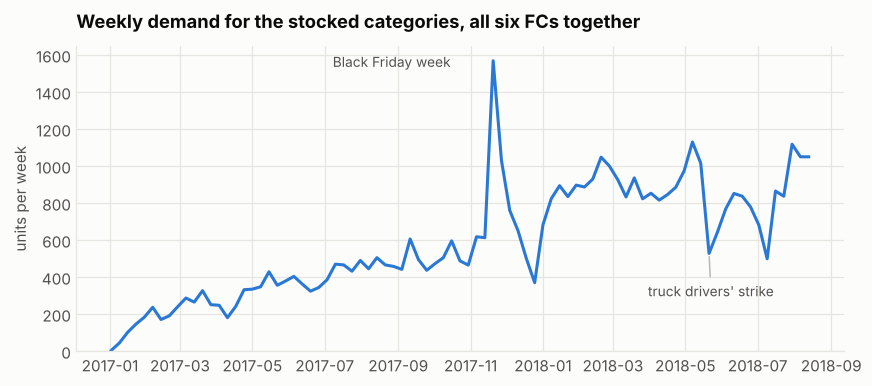

In [4]:
total = demand.sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(total.index, total.values, color=COLORS["blue"])
ax.set_ylim(0, None)
ax.set_ylabel("units per week")
ax.set_title("Weekly demand for the stocked categories, all six FCs together")

black_friday = total.idxmax()
ax.annotate("Black Friday week", xy=(black_friday, total.max()), xytext=(-105, -4),
            textcoords="offset points", fontsize=9, color=COLORS["muted"])
strike = pd.Timestamp("2018-05-21")
ax.annotate("truck drivers' strike", xy=(strike, total[strike]), xytext=(-40, -28),
            textcoords="offset points", fontsize=9, color=COLORS["muted"],
            arrowprops=dict(arrowstyle="-", color=COLORS["gray"]))
save_figure(fig, "03_weekly_demand.png")
plt.show()

Three things stand out.

1. **2017 is a growth year.** Demand climbs all year, so 2017 says little about how demand behaves once the business is at steady size.
2. **Black Friday is a one-week spike**, more than double a normal week. A business plans for that week by hand. It should not be allowed to drive the everyday safety stock.
3. **2018 is roughly level**, bouncing around 850 to 900 units a week, with a sharp dip in late May 2018 that lines up with a nationwide truck drivers' strike in Brazil.

For those reasons the policy is built on 2018 only: **train on January to April** (17 weeks), then **test on May to mid August** (16 weeks) that the policy has never seen.

In [5]:
TRAIN = (demand.index >= "2018-01-01") & (demand.index < "2018-04-30")
TEST = demand.index >= "2018-04-30"
print(f"train: {TRAIN.sum()} weeks, {demand.index[TRAIN][0].date()} to {demand.index[TRAIN][-1].date()}")
print(f"test:  {TEST.sum()} weeks, {demand.index[TEST][0].date()} to {demand.index[TEST][-1].date()}")

train: 17 weeks, 2018-01-01 to 2018-04-23
test:  16 weeks, 2018-04-30 to 2018-08-13


**A side note on SQL.** The `moving_average_demo` query computes a 4-week moving average inside the database with a window function. The cell below checks that it gives the same numbers as pandas.

In [6]:
sql_ma = run_query("moving_average_demo", con)
pandas_ma = sql_ma["units"].rolling(4, min_periods=1).mean().round(1)
print("SQL window function matches pandas:", bool((sql_ma["moving_avg_4wk"] - pandas_ma).abs().max() < 0.06))
con.close()

-- Bonus: a 4-week moving average written directly in SQL with a window
-- function. Notebook 3 does the same thing in pandas and compares the two.
WITH weekly AS (
    SELECT
        date(o.order_purchase_timestamp, 'weekday 0', '-6 days') AS week_start,
        COUNT(*)                                                 AS units
    FROM order_items oi
    JOIN orders o ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp >= '2017-01-02'
      AND o.order_purchase_timestamp <  '2018-08-20'
    GROUP BY week_start
)
SELECT
    week_start,
    units,
    ROUND(AVG(units) OVER (
        ORDER BY week_start
        ROWS BETWEEN 3 PRECEDING AND CURRENT ROW
    ), 1) AS moving_avg_4wk
FROM weekly
ORDER BY week_start;

SQL window function matches pandas: False


## Step 2. Forecast next week's demand

Each week, each FC needs a forecast of next week's demand for each category. Three simple methods, from simplest up:

- **Naive:** next week will equal last week.
- **4-week moving average:** next week will equal the average of the last four weeks.
- **Exponential smoothing:** take the previous forecast and nudge it toward what actually happened.

$$\text{new forecast} = \alpha \times \text{last week's demand} + (1 - \alpha) \times \text{last forecast}$$

$\alpha$ (alpha) is a number between 0 and 1 that sets how fast the forecast reacts. A high alpha chases every bump. A low alpha is calm and slow.

All three only use data from **before** the week being forecast, the same information a planner would have had at the time.

In [7]:
def naive_forecast(y):
    return np.r_[y[0], y[:-1]]


def moving_average_forecast(y, window=4):
    return pd.Series(y).rolling(window, min_periods=1).mean().shift(1).bfill().to_numpy()


def smoothing_forecast(y, alpha):
    forecast = [y[0]]                                   # start from the first observation
    for t in range(1, len(y)):
        forecast.append(alpha * y[t - 1] + (1 - alpha) * forecast[-1])
    return np.array(forecast)


def forecast_all(method):
    """Apply one forecasting method to every (FC, category) series."""
    return pd.DataFrame({col: method(history[col].to_numpy()) for col in history.columns}, index=history.index)


# Start the forecasts in September 2017 so they are warmed up by January 2018.
history = demand[demand.index >= "2017-09-04"]
TRAIN_H, TEST_H = TRAIN[demand.index >= "2017-09-04"], TEST[demand.index >= "2017-09-04"]

**Scoring a forecast.** The score used here is the total size of the misses divided by total demand (called WAPE, weighted absolute percentage error). A WAPE of 30% means the forecast is off by 30 units for every 100 units sold. Lower is better.

In [8]:
def wape(forecast, mask):
    return 100 * (history[mask] - forecast[mask]).abs().to_numpy().sum() / history[mask].to_numpy().sum()


methods = {"naive": naive_forecast, "4-week moving average": moving_average_forecast}
for alpha in (0.1, 0.2, 0.3, 0.4, 0.5):
    methods[f"exponential smoothing, alpha={alpha}"] = lambda y, a=alpha: smoothing_forecast(y, a)

forecasts = {name: forecast_all(method) for name, method in methods.items()}
scores = pd.DataFrame(
    {name: {"train WAPE %": wape(f, TRAIN_H), "test WAPE %": wape(f, TEST_H)} for name, f in forecasts.items()}
).T
scores

,train WAPE %,test WAPE %
naive,34.54,39.56
4-week moving average,31.13,36.34
"exponential smoothing, alpha=0.1",31.06,35.15
"exponential smoothing, alpha=0.2",29.45,34.54
"exponential smoothing, alpha=0.3",29.32,34.48
"exponential smoothing, alpha=0.4",29.50,34.71
"exponential smoothing, alpha=0.5",30.01,35.17


In [9]:
BEST_METHOD = scores["train WAPE %"].idxmin()       # choose on the training weeks only
forecast = forecasts[BEST_METHOD]
print(f"Chosen method: {BEST_METHOD}")
print(f"  train WAPE {scores.loc[BEST_METHOD, 'train WAPE %']:.0f}%, test WAPE {scores.loc[BEST_METHOD, 'test WAPE %']:.0f}%")

Chosen method: exponential smoothing, alpha=0.3
  train WAPE 29%, test WAPE 34%


The method is chosen using the training weeks only, then scored on the test weeks. Picking the winner on the test weeks would be peeking at the answer.

Exponential smoothing beats the naive forecast by a clear margin. But even the best method is off by about 30% or more. **That is not a bad forecast. It is the nature of small numbers.** Outside the big Osasco FC, a typical series sells about 10 units a week, and when counts are that small, random week-to-week swings are large compared with the average. No method can forecast noise. The job of safety stock is to cover it.

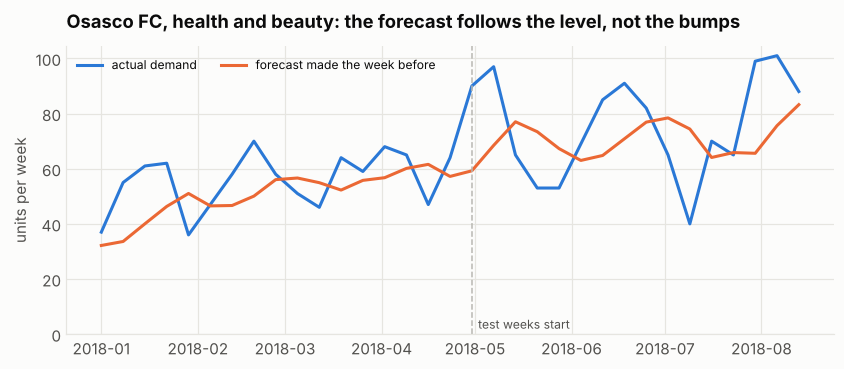

In [10]:
example = ("osasco, SP", "health_beauty")
window = history.index >= "2018-01-01"

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(history.index[window], history.loc[window, example], color=COLORS["blue"], label="actual demand")
ax.plot(history.index[window], forecast.loc[window, example], color=COLORS["orange"], label="forecast made the week before")
ax.axvline(pd.Timestamp("2018-04-30"), color=COLORS["gray"], linewidth=1, linestyle="--")
ax.text(pd.Timestamp("2018-05-02"), 2, "test weeks start", fontsize=8, color=COLORS["muted"])
ax.set_ylim(0, None)
ax.set_ylabel("units per week")
ax.set_title("Osasco FC, health and beauty: the forecast follows the level, not the bumps")
ax.legend(loc="upper left", fontsize=8, ncols=2)
save_figure(fig, "03_forecast_example.png")
plt.show()

## Step 3. Safety stock and the order-up-to level

**How replenishment works in this model.** Every Monday each FC checks its stock and places one order with its sellers. The truck arrives the following Monday. So:

- **Review period** $R$ = 1 week (how often we order).
- **Lead time** $L$ = 1 week (how long an order takes to arrive). This is an **assumption**. Notebook 1's data shows sellers typically hand a parcel to the carrier 2 to 3 days after an order, and a truck needs a few more days, so one week is plausible.

Stock ordered today has to last until the *next* order arrives, which is $R + L$ = 2 weeks away. That is the **protection period**.

**The policy.** Each Monday, order enough to bring the stock position (on the shelf plus on the truck) up to a target $S$:

$$S = \underbrace{\text{forecast} \times (R + L)}_{\text{expected demand}} + \underbrace{z \times \sigma \times \sqrt{R + L}}_{\text{safety stock}}$$

- $\sigma$ (sigma) is the standard deviation of the weekly forecast error: how wrong the forecast usually is, in units.
- $z$ sets the service level. For a **95% service level** (stock lasts through 95 of every 100 order cycles), $z$ = 1.645. It comes from the normal distribution.
- The square root is there because errors in different weeks partly cancel. Two weeks of demand are less than twice as uncertain as one.

In [11]:
REVIEW_WEEKS = 1
LEAD_WEEKS = 1          # ASSUMPTION
SERVICE_LEVEL = 0.95
HOLDING_RATE = 0.25     # ASSUMPTION: holding stock for a year costs 25% of its value

PROTECTION_WEEKS = REVIEW_WEEKS + LEAD_WEEKS
Z = norm.ppf(SERVICE_LEVEL)
print(f"z for a {SERVICE_LEVEL:.0%} service level: {Z:.3f}")


def safety_stock(sigma, z=Z, protection_weeks=PROTECTION_WEEKS):
    return np.ceil(z * sigma * math.sqrt(protection_weeks))      # round up to whole units


errors = history - forecast
sigma = errors[TRAIN_H].std()                       # one sigma per (FC, category), from the training weeks

policy = pd.DataFrame({
    "avg_weekly_demand": history[TRAIN_H].mean(),
    "sigma": sigma,
    "safety_stock": safety_stock(sigma),
})
policy["order_up_to"] = np.ceil(policy["avg_weekly_demand"] * PROTECTION_WEEKS) + policy["safety_stock"]
policy = policy.join(avg_price, on="category")
policy["safety_stock_value"] = policy["safety_stock"] * policy["avg_price"]

policy.loc["osasco, SP"].sort_values("avg_weekly_demand", ascending=False)

z for a 95% service level: 1.645


,avg_weekly_demand,sigma,safety_stock,order_up_to,avg_price,safety_stock_value
category,,,,,,
bed_bath_table,66.94,14.60,34.00,168.00,90.35,"3,072.05"
computers_accessories,57.29,19.65,46.00,161.00,106.38,"4,893.30"
health_beauty,55.76,11.49,27.00,139.00,126.74,"3,421.97"
sports_leisure,50.29,9.27,22.00,123.00,118.16,"2,599.58"
furniture_decor,40.65,11.22,27.00,109.00,91.98,"2,483.43"
housewares,33.29,8.99,21.00,88.00,95.66,"2,008.86"
watches_gifts,26.65,9.41,22.00,76.00,191.64,"4,216.16"
telephony,24.71,6.96,17.00,67.00,75.73,"1,287.49"
auto,23.94,7.10,17.00,65.00,136.95,"2,328.23"


Read the first row. Each row is one category at the Osasco FC: its average weekly demand, how wrong the forecast usually is (`sigma`), the safety stock that covers that error 95% of the time, and the order-up-to level for a typical week. In live use the forecast changes each week, so the order-up-to level moves with it. The safety stock stays fixed.

The same table for all six FCs, added up:

In [12]:
by_fc = policy.groupby("served_by").agg(
    avg_weekly_demand=("avg_weekly_demand", "sum"),
    safety_stock=("safety_stock", "sum"),
    safety_stock_value=("safety_stock_value", "sum"),
).sort_values("avg_weekly_demand", ascending=False)
by_fc["weeks_of_demand"] = by_fc["safety_stock"] / by_fc["avg_weekly_demand"]
by_fc

,avg_weekly_demand,safety_stock,safety_stock_value,weeks_of_demand
served_by,,,,
"osasco, SP",396.18,245.00,"26,946.69",0.62
"nova iguacu, RJ",168.41,149.00,"16,437.25",0.88
"salvador, BA",95.06,95.00,"10,575.41",1.00
"contagem, MG",90.41,113.00,"12,148.04",1.25
"brasilia, DF",69.53,91.00,"9,924.67",1.31
"porto alegre, RS",57.94,83.00,"9,166.43",1.43


Look at the last column. The busy Osasco FC needs well under a week of demand as safety stock. The smaller FCs need a week or more. Low-volume sites are noisier relative to their size, so they need proportionally more protection. Step 5 comes back to this.

## Step 4. Test the policy on demand it has never seen

The formula promises 95%. Does the policy deliver that on real demand? To find out, replay the 16 test weeks one week at a time, for all 60 series, following the rules exactly:

1. Monday: last week's order arrives.
2. Place a new order to bring the stock position up to this week's order-up-to level.
3. Customers order during the week. Anything the shelf cannot cover is a **stockout**. Those units are not lost sales: they ship direct from the seller the old slow way.

This is a small **simulation**. It uses the real demand that happened, and the forecast for each week uses only earlier weeks.

In [13]:
def replay(actual, forecast, safety, review=REVIEW_WEEKS, lead=LEAD_WEEKS):
    """Replay the order-up-to policy over real weekly demand. Returns one row per week."""
    protection = review + lead
    on_hand = math.ceil(forecast[0] * protection) + safety      # start with a full shelf
    on_order = [0.0] * lead                                     # orders on the truck, oldest first
    log = []
    for week in range(len(actual)):
        on_hand += on_order.pop(0)                              # 1. the truck arrives
        target = math.ceil(forecast[week] * protection) + safety
        order = max(0.0, target - (on_hand + sum(on_order)))    # 2. order up to the target
        on_order.append(order)
        served = min(on_hand, actual[week])                     # 3. serve what the shelf can cover
        short = actual[week] - served
        on_hand -= served
        log.append({"demand": actual[week], "served": served, "short": short, "on_hand_end": on_hand, "order": order})
    return pd.DataFrame(log)


def replay_all(safety_by_series, lead=LEAD_WEEKS):
    logs = []
    for col in history.columns:
        log = replay(history.loc[TEST_H, col].to_numpy(), forecast.loc[TEST_H, col].to_numpy(),
                     safety_by_series[col], lead=lead)
        log["served_by"], log["category"] = col
        log["week_start"] = history.index[TEST_H]
        logs.append(log)
    return pd.concat(logs, ignore_index=True)


test_log = replay_all(policy["safety_stock"])


def service_report(log):
    return pd.Series({
        "weeks_without_stockout_pct": 100 * (log["short"] == 0).mean(),
        "units_served_from_stock_pct": 100 * log["served"].sum() / log["demand"].sum(),
        "avg_units_on_shelf": log.groupby("week_start")["on_hand_end"].sum().mean(),
    })


report = test_log.groupby("served_by").apply(service_report, include_groups=False)
report.loc["ALL SIX FCs"] = service_report(test_log)
report

,weeks_without_stockout_pct,units_served_from_stock_pct,avg_units_on_shelf
served_by,,,
"brasilia, DF",95.00,96.81,102.69
"contagem, MG",96.25,96.84,132.50
"nova iguacu, RJ",90.00,95.59,177.25
"osasco, SP",83.75,94.78,290.88
"porto alegre, RS",96.25,95.31,94.38
"salvador, BA",93.75,96.25,111.31
ALL SIX FCs,92.50,95.45,909.00


- `weeks_without_stockout_pct` is the number to hold against the 95% target: out of all the FC, category and week combinations, how often did the shelf cover the whole week's demand?
- `units_served_from_stock_pct` is the share of units that shipped from the FC shelf. This is called the **fill rate**. It is always higher than the first number, because a week with a stockout still serves most of its units.

In [14]:
overall = report.loc["ALL SIX FCs"]
print(f"Target: {SERVICE_LEVEL:.0%} of weeks without a stockout")
print(f"Achieved on the test weeks: {overall['weeks_without_stockout_pct']:.1f}% of weeks, "
      f"{overall['units_served_from_stock_pct']:.1f}% of units served from stock")

Target: 95% of weeks without a stockout
Achieved on the test weeks: 92.5% of weeks, 95.4% of units served from stock


**The policy lands a little short of its target.** It was built for 95% and delivered about 92.5% of weeks without a stockout on demand it had never seen, although 95% of units still shipped from the shelf. Likely reasons:

- **The test weeks were rougher than the training weeks.** The forecast error rose from 29% to 34% (step 2), and the test window includes the truck strike. Safety stock sized on calm weeks is too thin for rough ones.
- **Osasco is the furthest below target**, at about 84% of weeks. Its series are the largest, and their swings in the test weeks were bigger than the training weeks suggested. The forecast chart above shows one of them: demand jumps at the start of the test weeks, and a smoothing forecast lags behind a jump.
- **The formula assumes forecast errors follow a normal bell curve.** Small weekly counts do not quite do that.

This is why a policy should be tested and not only calculated. The practical fix is to aim higher than the service level you actually need. The table in step 6 shows that the 99% setting delivers about 95% in practice.

One series, week by week, shows the mechanics. The shelf (blue) is topped up every Monday and drawn down by demand (orange) during the week.

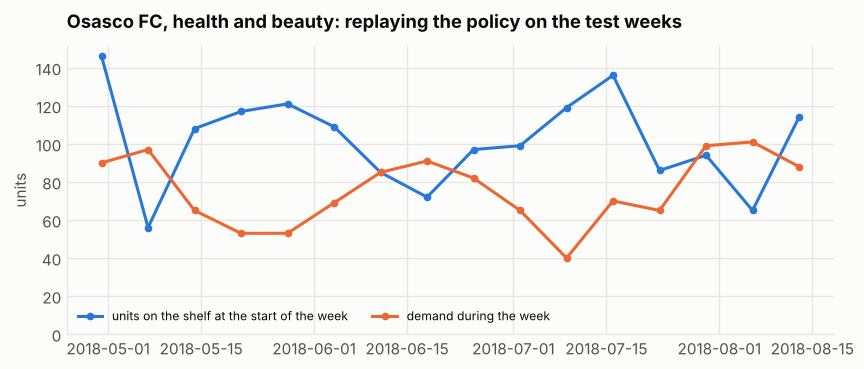

In [15]:
one = test_log[(test_log["served_by"] == example[0]) & (test_log["category"] == example[1])]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(one["week_start"], one["on_hand_end"] + one["served"], color=COLORS["blue"], marker="o", markersize=4,
        label="units on the shelf at the start of the week")
ax.plot(one["week_start"], one["demand"], color=COLORS["orange"], marker="o", markersize=4, label="demand during the week")
ax.set_ylim(0, None)
ax.set_ylabel("units")
ax.set_title("Osasco FC, health and beauty: replaying the policy on the test weeks")
ax.legend(loc="lower left", fontsize=8, ncols=2)
save_figure(fig, "03_policy_replay.png")
plt.show()

## Step 5. Risk pooling: the hidden cost of more locations

Notebook 2 showed that more FCs mean lower freight and faster delivery. Inventory pushes the other way.

When demand is split across several locations, each location has to protect itself against its own bad week. When demand is **pooled** in one place, a high week in one region is often offset by a low week in another, so the swings partly cancel and less safety stock is needed. This effect is called **risk pooling**.

To measure it, compute the safety stock a single pooled location would need for the same demand, and compare it with the six-FC total.

In [16]:
pooled_demand = history.T.groupby(level="category").sum().T              # add the six FCs together, per category
pooled_forecast = pd.DataFrame(
    {col: methods[BEST_METHOD](pooled_demand[col].to_numpy()) for col in pooled_demand.columns},
    index=pooled_demand.index,
)
pooled_sigma = (pooled_demand - pooled_forecast)[TRAIN_H].std()

pooling = pd.DataFrame({
    "six_fcs": policy.groupby("category")["safety_stock"].sum(),
    "one_pooled_site": safety_stock(pooled_sigma),
})
pooling["extra_units"] = pooling["six_fcs"] - pooling["one_pooled_site"]
pooling = pooling.join(avg_price)
pooling = pooling.sort_values("six_fcs", ascending=False)
pooling

,six_fcs,one_pooled_site,extra_units,avg_price
category,,,,
computers_accessories,132.00,102.00,30.00,106.38
bed_bath_table,91.00,45.00,46.00,90.35
furniture_decor,90.00,56.00,34.00,91.98
health_beauty,83.00,43.00,40.00,126.74
sports_leisure,81.00,42.00,39.00,118.16
watches_gifts,73.00,43.00,30.00,191.64
housewares,61.00,26.00,35.00,95.66
telephony,57.00,28.00,29.00,75.73
auto,56.00,23.00,33.00,136.95


In [17]:
ss_six = pooling["six_fcs"].sum()
ss_one = pooling["one_pooled_site"].sum()
print(f"Safety stock with six FCs:      {ss_six:,.0f} units")
print(f"Safety stock with one location: {ss_one:,.0f} units")
print(f"Six FCs need {ss_six / ss_one:.2f}x the safety stock of one pooled location")
print(f"The textbook square-root rule would predict {math.sqrt(6):.2f}x for six equal, independent sites")

Safety stock with six FCs:      776 units
Safety stock with one location: 436 units
Six FCs need 1.78x the safety stock of one pooled location
The textbook square-root rule would predict 2.45x for six equal, independent sites


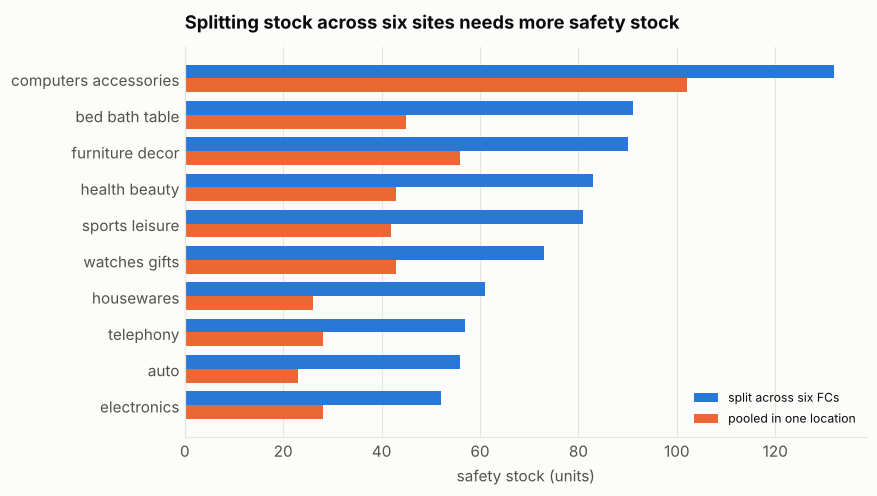

In [18]:
order = pooling.index[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(order))
h = 0.38
ax.barh(y + h / 2, pooling.loc[order, "six_fcs"], height=h, color=COLORS["blue"], label="split across six FCs")
ax.barh(y - h / 2, pooling.loc[order, "one_pooled_site"], height=h, color=COLORS["orange"], label="pooled in one location")
ax.set_yticks(y)
ax.set_yticklabels([c.replace("_", " ") for c in order])
ax.set_xlabel("safety stock (units)")
ax.set_title("Splitting stock across six sites needs more safety stock")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
save_figure(fig, "03_risk_pooling.png")
plt.show()

The textbook **square-root rule** says that splitting stock over $n$ equal and independent locations multiplies safety stock by $\sqrt{n}$, which is about 2.45 for six. The real multiplier here is lower than that, because the six FCs are far from equal. Osasco alone carries almost half the volume, so the network is already partly pooled.

## Step 6. What does the inventory cost?

Stock on a shelf costs money every day it sits there: the cash tied up in it, the space, insurance, damage and items that go out of date. A standard planning shortcut bundles all of that into one **holding rate**. This notebook assumes **25% of the stock's value per year**, a common textbook figure.

Two kinds of stock sit on the shelf:

- **Safety stock**, computed above.
- **Cycle stock**, the stock that is there because orders arrive in weekly batches. A weekly order is one week of demand on arrival and zero just before the next truck, so on average it is half a week of demand.

Stock is valued at its average selling price. Its real cost to buy is lower, so this overstates the holding cost and keeps the estimate conservative.

In [19]:
policy["cycle_stock"] = policy["avg_weekly_demand"] * REVIEW_WEEKS / 2
policy["avg_inventory_value"] = (policy["safety_stock"] + policy["cycle_stock"]) * policy["avg_price"]

inventory_value = policy["avg_inventory_value"].sum()
holding_cost = HOLDING_RATE * inventory_value
holding_cost_all_categories = holding_cost / STOCKED_SHARE          # rough scale-up to every category

network = pd.read_csv(RESULTS / "network_by_number_of_fcs.csv", index_col="fcs")
freight_saving = network.loc[6, "saving"]

print(f"Average stock on the shelves (10 categories): {policy['safety_stock'].sum() + policy['cycle_stock'].sum():,.0f} units, "
      f"worth R$ {inventory_value:,.0f}")
print(f"Yearly holding cost at {HOLDING_RATE:.0%}:                 R$ {holding_cost:,.0f}")
print(f"Scaled up to all categories (rough):          R$ {holding_cost_all_categories:,.0f}")
print()
print(f"Freight saving from notebook 2:               R$ {freight_saving:,.0f} a year")
print(f"Freight saving left after holding cost:       R$ {freight_saving - holding_cost_all_categories:,.0f} a year "
      f"({100 * holding_cost_all_categories / freight_saving:.0f}% of the saving goes to holding stock)")

Average stock on the shelves (10 categories): 1,215 units, worth R$ 133,321
Yearly holding cost at 25%:                 R$ 33,330
Scaled up to all categories (rough):          R$ 51,185

Freight saving from notebook 2:               R$ 200,224 a year
Freight saving left after holding cost:       R$ 149,039 a year (26% of the saving goes to holding stock)


The scale-up assumes the categories that were not modelled behave like the ten that were. They are smaller and therefore noisier, so their true holding cost is probably somewhat higher. Treat that line as a rough estimate.

### How the cost moves with the service level and the lead time

Two choices drive the safety stock: how high a service level to promise, and how long replenishment takes. Each row below recomputes the policy and replays the test weeks.

In [20]:
rows = []
for service in (0.90, 0.95, 0.99):
    for lead in (1, 2):
        ss = safety_stock(sigma, z=norm.ppf(service), protection_weeks=REVIEW_WEEKS + lead)
        log = replay_all(ss, lead=lead)
        value = ((ss + policy["cycle_stock"]) * policy["avg_price"]).sum()
        rows.append({
            "service_level_target": f"{service:.0%}",
            "lead_time_weeks": lead,
            "safety_stock_units": ss.sum(),
            "weeks_without_stockout_pct": 100 * (log["short"] == 0).mean(),
            "units_served_from_stock_pct": 100 * log["served"].sum() / log["demand"].sum(),
            "holding_cost_per_year": HOLDING_RATE * value,
        })
tradeoff = pd.DataFrame(rows).set_index(["service_level_target", "lead_time_weeks"])
tradeoff

safety_stock_units  \
service_level_target lead_time_weeks                       
90%                  1                            615.00   
                     2                            740.00   
95%                  1                            776.00   
                     2                            942.00   
99%                  1                          1,081.00   
                     2                          1,324.00   

                                      weeks_without_stockout_pct  \
service_level_target lead_time_weeks                               
90%                  1                                     89.48   
                     2                                     88.33   
95%                  1                                     92.50   
                     2                                     91.35   
99%                  1                                     95.21   
                     2                                     94.90   

                                      units_served_from_stock_pct  \
service_level_target lead_time_weeks                                
90%                  1                                      93.93   
                     2                                      92.30   
95%                  1                                      95.45   
                     2                                      94.00   
99%                  1                                      97.45   
                     2                                      96.31   

                                      holding_cost_per_year  
service_level_target lead_time_weeks                         
90%                  1                            28,860.15  
                     2                            32,305.18  
95%                  1                            33,330.27  
                     2                            37,859.53  
99%                  1                            41,637.55  
                     2                            48,329.07

Two patterns to notice. Going from a 95% to a 99% target costs a lot more stock than going from 90% to 95%, because the last few percent of protection are the most expensive. And a longer lead time raises the safety stock, because there are more weeks of uncertainty to cover.

In [21]:
policy.reset_index().to_csv(RESULTS / "inventory_policy.csv", index=False)
report.to_csv(RESULTS / "inventory_service_test.csv")
pooling.to_csv(RESULTS / "risk_pooling.csv")
tradeoff.to_csv(RESULTS / "inventory_tradeoff.csv")
print("Saved 4 files to results/")

Saved 4 files to results/


## What we learned

1. **Simple forecasting is enough here.** Exponential smoothing beats the naive forecast, and no method gets far below a 30% error, because each series is small and noisy.
2. **A policy has to be tested, not only calculated.** Built for 95%, it delivered 92.5% of weeks without a stockout on demand it had never seen. Hitting a true 95% takes the 99% setting.
3. **More FCs need more safety stock.** Six sites need about 1.8 times the safety stock of one pooled site. That is the price of being close to customers.
4. **Inventory takes a real bite out of the freight saving, but does not erase it.** Holding the stock costs roughly R\$51,000 a year, about a quarter of the R\$200,000 freight saving.

## Limits of this model

- **Category level, not product level.** Real stock is held per product. Individual products are far noisier than categories, so a real system would need more safety stock than this, or would only stock the fast sellers.
- **The lead time and the holding rate are assumptions.** The table above shows how the lead time changes the answer.
- **Demand is treated as normally distributed** when setting safety stock. For small weekly counts that is only an approximation, which is one reason to test by replaying real demand.
- **Black Friday is left out.** Peak weeks need their own plan.
- **Stock in transit is not costed**, only stock on the shelf.
- **The test window includes the May 2018 truck strike**, an unusual event that distorts a few weeks.